# Waveguide bend: quickstart
Wavelength dependent S-parameters for Euler waveguide bend in SOI

## Setup 

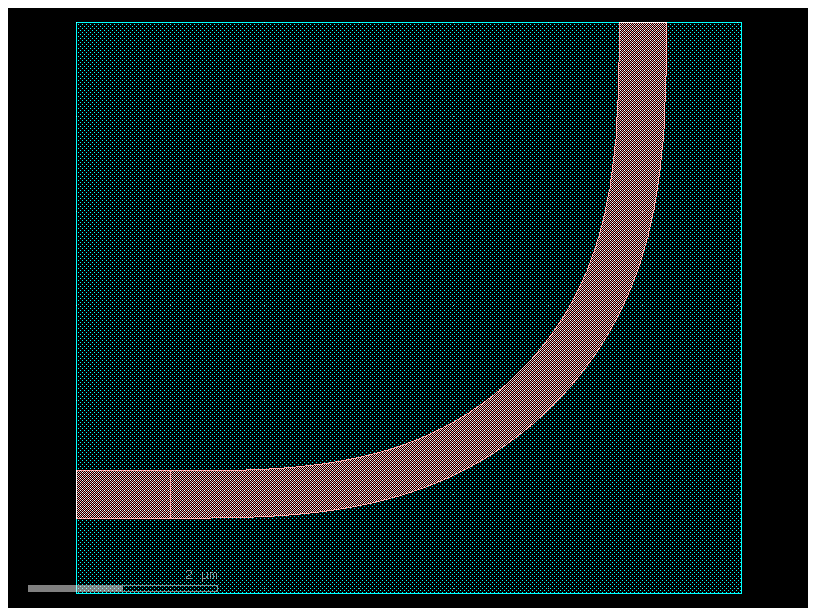

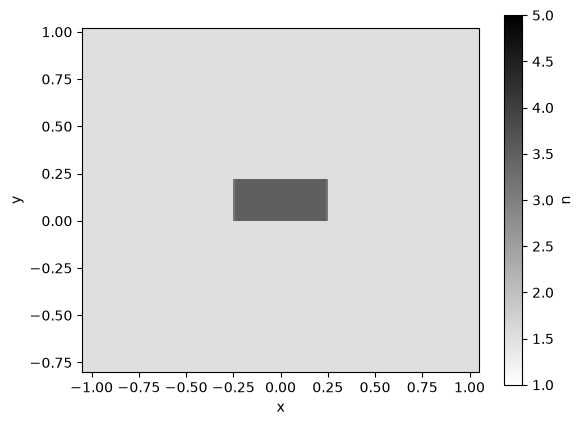

using simulation folder runs/bend


In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt

import gdsfactory as gf
from gdsfactory.technology import LogicalLayer, LayerLevel, LayerStack
import luminescent as lumi

# simulation folder
path = os.path.join("runs", "bend")

# dims [um]
# length units are arbitrary so long as they're consistent
r=5
w_wg = 0.5
h_wg = 0.22
bend_type = "euler"

# wavelengths [um]. 
# spectrum computed from single FDTD run. more wavelengths slightly increases runtime
wavelength = 1.55
bandwidth = 0.1
nwls = 11
wavelengths = np.linspace(wavelength - bandwidth / 2, wavelength + bandwidth / 2, nwls)

# "euler" or "circular"
def setup(path,wavelength,wavelengths, r,w_wg,h_wg,bend_type):
    # simulation parameters
    nres = 6
    subpixel_smoothing = 1
    shutoff = 1e-3
    tmax = 100
    PML_decay = [0.001, 0.001, 0.1]  # x y z
    views = [lumi.view("Hz", y="half", z=h_wg / 2)]
    shot_every = 10 # movie [periods]

    boundaries = ["PML", "PML", "PML"]

    # margins
    margin = 0.8
    source_offset = 1

    # vertical dims
    zmargin = 0.8
    zmin = -zmargin
    zmax = h_wg + zmargin

    # materials
    core = "Si"
    clad = "SiO2"
    materials = {
        "Si": lumi.material(3.5),
        "SiO2": lumi.material(1.5),
    }
    background = clad

    # layers
    WG = 1, 0
    CLAD = 2, 0

    layer_stack =     LayerStack(
            layers={
                "core": LayerLevel(
                    layer=LogicalLayer(layer=WG),
                    thickness=h_wg,
                    zmin=0,
                    material=core,
                    mesh_order=1,
                )
            }
        )

    # make component in gdsfactory. alternatively can import .gds into gdsfactory
    c = gf.Component()

    # Euler or circular bend
    if bend_type == "euler":
        b = c << gf.components.bend_euler(r)
    elif bend_type == "circular":
        b = c << gf.components.bend_circular(r)
    s = c << gf.components.straight(length=source_offset, width=w_wg)

    s.connect("o2", b.ports["o1"])
    c << gf.components.bbox(component=c, layer=CLAD, right=margin, bottom=margin)

    c.add_port("o1", port=b.ports["o1"])
    c.add_port("o2", port=b.ports["o2"])
    c.plot()

    bbox = c.bbox_np().tolist()
    bbox[0].append(zmin)
    bbox[1].append(zmax)

    # sources, monitors
    w_port = w_wg + 2 * margin
    frames = [
        lumi.plane_frame(
            "wg_mode",
            start=[-w_port / 2, zmin],
            stop=[w_port / 2, zmax],
            boundaries=["PML", "PML"],
            nmodes=1,
            modes="auto",
            wls_mode_solver=[wavelength],
        ),
        lumi.points_frame("wg_signal", points=[[0, 0]], time_domain=True),
    ]

    sources = [
        lumi.gf_source(
            "o1", c, layer_stack, source_offset,
            frame="wg_mode",
            wl=wavelength,
            bandwidth=max(max(wavelengths) - min(wavelengths), wavelength / 8),
        )
    ]

    monitors = [
        # modal monitors
        lumi.gf_monitor(
            "o1", c, layer_stack,
            frame="wg_mode",
        ),
        lumi.gf_monitor(
            "o2", c, layer_stack,
            frame="wg_mode",
            mirrored=True,
        ),
        # time traces (not necessary for S-parameters but for visualizing the signal)
        # lumi.gf_monitor("o2", c, layer_stack, name="o2_signal", frame="wg_signal"),
    ]

    # writes .obj mesh files from gdsfactory component
    lumi.mesh(path, c, layer_stack, materials, zmin, zmax)

    # writes setup file
    lumi.setup(
        path=path,
        wl=wavelength,
        wls=wavelengths,
        materials=materials,
        background=background,
        boundaries=boundaries,
        bbox=bbox,
        #
        frames=frames,
        sources=sources,
        monitors=monitors,
        #
        nres=nres,
        subpixel_smoothing=subpixel_smoothing,
        tmax=tmax,
        PML_decay=PML_decay,
        #
        views=views,
        shot_every=shot_every,
        shutoff=shutoff,
    )

setup(path, wavelength, wavelengths, r, w_wg, h_wg,bend_type)


## Solve

backend using simulation folder runs/bend
setting up simulation...
processing geometry bodies...
generating voxels...
voxelation: 2.744655 seconds (14.44 M allocations: 770.385 MiB, 1.96% gc time, 328.84% compilation time)
Yee mode λ=1.0: neff 2.5174
making sources o1 ...
making monitors o1 o2 ...
run: runs/bend
processor: GPU
cpu threads: 48

nres: 6.0
courant: 0.9
subpixel_smoothing: 1
  
boundaries: [:PML :PML; :PML :PML; :PML :PML]

sources
   o1: -1, 0.0, 0 

monitors
   o1: 0, 0, 0 
   o2: 5, 5, 0 

original size: (94, 81, 19)
padded size: (131, 118, 31)
cell count: 479,198

step size: 28.0 steps/period
source duration: 7.96 periods

max time: 100.0 periods
max steps: 2,800
max load: 1,341,754,400 cell-steps
energy decay threshold: 0.001

running simulation...
accumulating dft field...
period 10, decay: 1.0, 0.86 seconds/period, 15.57 Mcells/s
period 20, decay: 0.99, 0.003 seconds/period, 4672.17 Mcells/s
period 30.0, decay: 0.97, 0.003 seconds/period, 4760.55 Mcells/s
period 36.

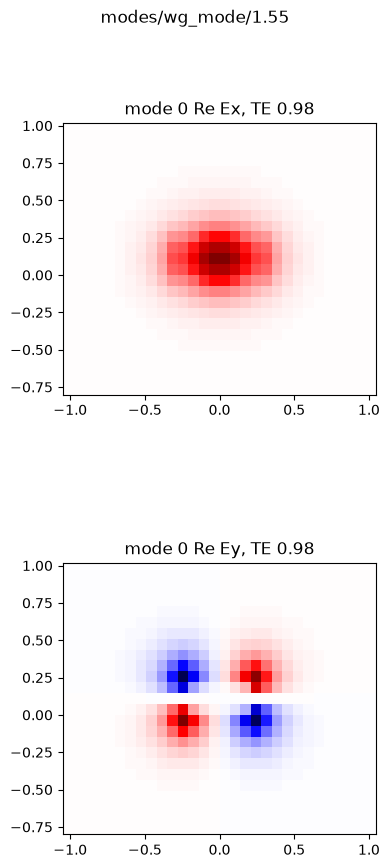

In [2]:
lumi.solve(path)

## Movie

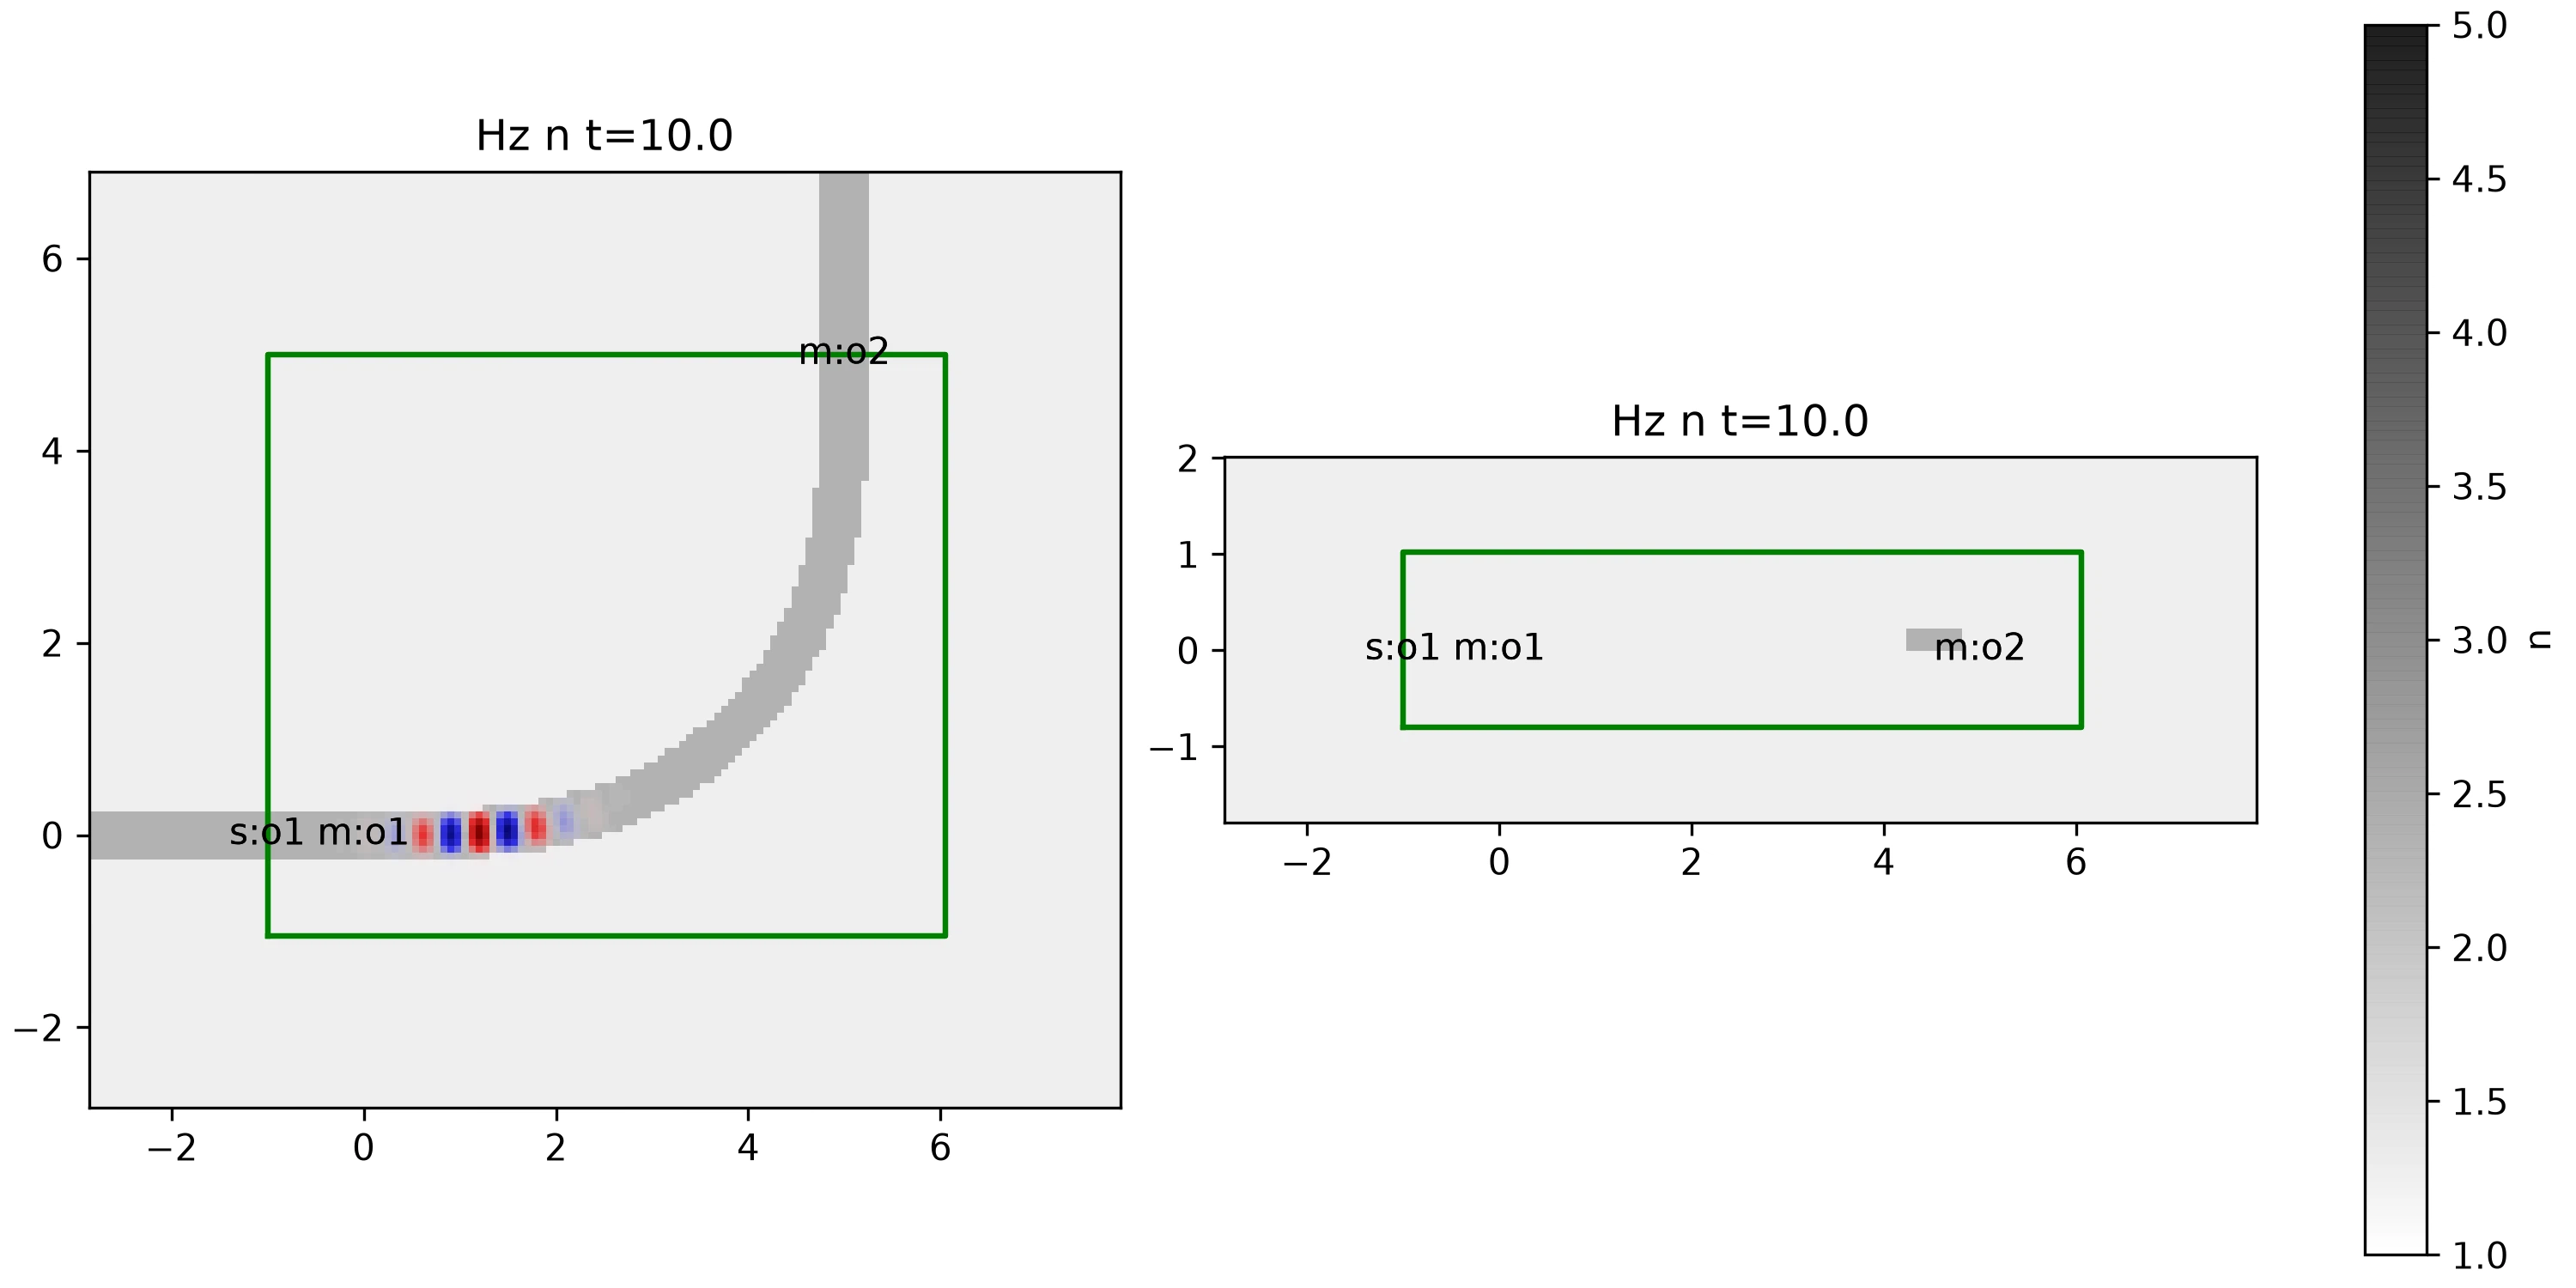

In [3]:
lumi.movie(path)

## Results

loading solution from runs/bend
may take a minute if simulation folder is remotely mounted
S21 power 1.55um: 0.9939143412704371
S11 power 1.55um: 0.00128286880260566


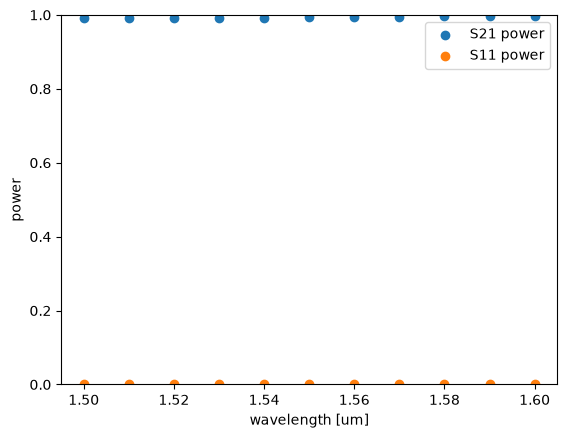

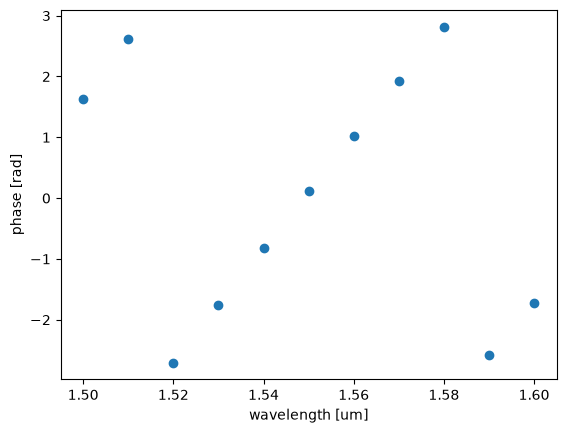

In [4]:
sol = lumi.load(path)
o1 = sol["monitors"]["o1"]
o2 = sol["monitors"]["o2"]

# + denotes forward propagating mode (wrt port monitor normal)
S21 = o2["modes"][0]["+"] / o1["modes"][0]["-"]
S11 = o1["modes"][0]["+"] / o1["modes"][0]["-"]

mid=nwls//2
S21_=np.abs(S21[mid])**2
S11_=np.abs(S11[mid])**2
print("S21 power 1.55um:", S21_)
print("S11 power 1.55um:", S11_)

plt.figure()
plt.scatter(wavelengths, np.abs(S21)**2, label="S21 power")
plt.scatter(wavelengths, np.abs(S11)**2, label="S11 power")
plt.xlabel("wavelength [um]")
plt.ylabel("power")
plt.ylim(0, 1)
plt.legend()
plt.show()

plt.figure()
plt.scatter(wavelengths, np.angle(S21), label="S21 phase")
plt.xlabel("wavelength [um]")
plt.ylabel("phase [rad]")
plt.show()